# Covariates

**Purpose:** build the merchant covariates for the logistic regression.

- **Input:** `CLEAN_DATA_PATH` (clean merchant-day data)
- **Output:** `COVARIATES_PATH` (one row per merchant)

**Steps**
1. Read the data.
2. Aggregate to one row per merchant; summary table.
3. Each variable: raw distribution, then decide type and classes.
4. Build, save and summarize the covariates.

**Notes**
- Decisions use each variable's own distribution, not the outcome.
- Uses the whole period; the model recomputes covariates per cutoff window.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

CLEAN_DATA_PATH = Path("output/merchant_day.pkl")
COVARIATES_PATH = Path("output/merchant_covariates.pkl")

## 1. Read data

In [2]:
df = pd.read_pickle(CLEAN_DATA_PATH)
df.head()

,date,merchant,subscription_volume,checkout_volume,payment_link_volume,total_volume,industry,first_charge_date,country,business_size
0,2041-05-01,5d03e714,0.0,0.00,0.0,4253.40,Education,2032-02-13,US,medium
1,2041-05-01,da22f154,0.0,0.00,0.0,173.26,Others,2031-10-16,US,small
2,2041-05-01,687eebc8,794.0,0.00,0.0,794.00,Software,2032-07-23,US,small
3,2041-05-01,de478470,2684.0,0.00,0.0,2684.00,Software,2033-03-15,US,small
4,2041-05-01,1e719b8a,0.0,198.95,0.0,198.95,Business services,2035-02-12,IT,small


## 2. One row per merchant

Sums, counts and first/last values only. Volume excludes Subscriptions.

In [3]:
END = df["date"].max()

g = df.assign(non_sub_volume=df["total_volume"] - df["subscription_volume"]).groupby("merchant")
merchants = g[["industry", "country", "business_size", "first_charge_date"]].first()
merchants["first_seen"] = g["date"].min()
merchants["last_seen"] = g["date"].max()
merchants["active_days"] = g.size()
merchants["non_sub_volume"] = g["non_sub_volume"].sum()
merchants["checkout_volume"] = g["checkout_volume"].sum()
merchants["payment_link_volume"] = g["payment_link_volume"].sum()

print(f"{len(merchants):,} merchants")
merchants.head()

23,619 merchants


,industry,country,business_size,first_charge_date,first_seen,last_seen,active_days,non_sub_volume,checkout_volume,payment_link_volume
merchant,,,,,,,,,,
00085cb5,Software,BG,small,2041-01-28,2041-05-03,2042-06-07,48,51600.00,51600.0,0.0
000a45ba,Others,US,small,2040-06-01,2041-06-02,2042-06-21,37,500.00,0.0,0.0
000e2c0e,Education,SG,small,2039-09-21,2041-05-11,2042-06-05,73,4668.83,0.0,0.0
001111d7,Transportation & car rental,SK,small,2042-04-24,2042-04-24,2042-06-22,9,18659.95,0.0,0.0
0015c036,Others,US,small,2041-02-27,2041-05-06,2042-05-09,68,0.00,138.0,0.0


### Summary table

In [4]:
QUANTILES = {"min": 0, "25%": 0.25, "50%": 0.5, "75%": 0.75, "99%": 0.99, "max": 1}


def column_summary(data):
    rows = {}
    for col in data.columns:
        s = data[col]
        row = {"dtype": str(s.dtype), "missing": s.isna().sum()}
        if pd.api.types.is_bool_dtype(s):
            row.update({"levels": 2, "most common": s.mode()[0], "count": s.value_counts().iloc[0]})
        elif pd.api.types.is_numeric_dtype(s):
            row.update({name: round(s.quantile(q), 2) for name, q in QUANTILES.items()})
        elif pd.api.types.is_datetime64_any_dtype(s):
            row.update({name: s.quantile(q).date() for name, q in QUANTILES.items()})
        else:
            counts = s.value_counts()
            row.update({"levels": s.nunique(), "most common": counts.index[0], "count": counts.iloc[0]})
        rows[col] = row
    columns = ["dtype", "missing", "levels", "most common", "count", *QUANTILES]
    return pd.DataFrame(rows).T.reindex(columns=columns).fillna("")

In [5]:
column_summary(merchants)

,dtype,missing,levels,most common,count,min,25%,50%,75%,99%,max
industry,category,7,29,Business services,3143,,,,,,
country,category,0,44,US,8592,,,,,,
business_size,category,0,3,small,22845,,,,,,
first_charge_date,datetime64[us],26,,,,2030-11-07,2039-06-25,2040-12-06,2041-09-22,2042-06-13,2042-06-22
first_seen,datetime64[us],0,,,,2041-05-01,2041-05-04,2041-06-20,2041-11-24,2042-06-15,2042-06-22
last_seen,datetime64[us],0,,,,2041-05-01,2042-01-26,2042-05-31,2042-06-20,2042-06-22,2042-06-22
active_days,int64,0,,,,1.0,3.0,14.0,73.0,418.0,418.0
non_sub_volume,float64,0,,,,0.0,136.23,1793.59,14943.56,1604968.88,989263609.55
checkout_volume,float64,0,,,,0.0,0.0,0.0,0.0,96423.18,16267923.47
payment_link_volume,float64,0,,,,0.0,0.0,0.0,0.0,20737.01,1212347.0


## 3. Raw distributions, variable by variable

In [6]:
def class_table(col):
    counts = merchants[col].value_counts(dropna=False)
    return pd.DataFrame({"merchants": counts, "% of merchants": (counts / len(merchants) * 100).round(1)})


def plot_hist(ax, values, title, xlabel):
    ax.hist(values.dropna(), bins=40, edgecolor="white")
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("merchants")

### 3.1 `industry`

In [7]:
class_table("industry")

,merchants,% of merchants
industry,,
Business services,3143,13.3
Software,2167,9.2
Merchandise,1987,8.4
Personal services,1922,8.1
Others,1729,7.3
Digital goods,1379,5.8
Education,1331,5.6
Clothing & accessory,1303,5.5
Food & drink,1275,5.4


The 9 industries with at least 5% of merchants keep their own class: Business services, Software, Merchandise, Personal services, Others, Digital goods, Education, Clothing & accessory, and Food & drink. The other 21 industries and the 7 missing values are merged into Others.

### 3.2 `country`

In [8]:
class_table("country")

,merchants,% of merchants
country,,
US,8592,36.4
GB,3476,14.7
FR,1700,7.2
AU,1378,5.8
CA,1323,5.6
ES,926,3.9
IT,821,3.5
JP,580,2.5
DE,507,2.1


The 5 countries with at least 5% of merchants keep their own class: US, GB, FR, AU and CA. The other countries are grouped into 3 regions, each also above 5%:

| Region | Countries |
|---|---|
| Western & Northern Europe | DE, IE, CH, NL, BE, AT, LU, SE, NO, DK, FI, EE, LV, LT |
| Southern & Eastern Europe | ES, IT, PT, GR, SI, HR, MT, GI, CY, PL, RO, CZ, SK, BG, HU |
| Rest of world | JP, IN, NZ, HK, SG, MY, TH, AE, MX, BR |

### 3.3 `business_size`

In [9]:
class_table("business_size")

,merchants,% of merchants
business_size,,
small,22845,96.7
medium,622,2.6
large,152,0.6


Medium and large are merged into one class, giving two: small and medium/large.

### 3.4 `first_charge_date`

count                         23593
mean     2040-05-06 00:05:07.616666
min             2030-11-07 00:00:00
25%             2039-06-25 00:00:00
50%             2040-12-06 00:00:00
75%             2041-09-22 00:00:00
max             2042-06-22 00:00:00
Name: first_charge_date, dtype: object

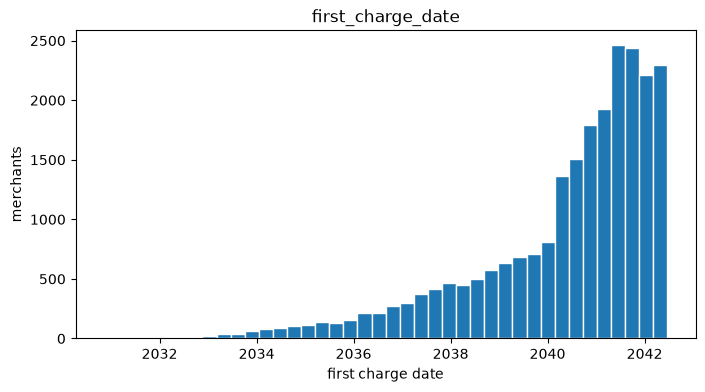

In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
plot_hist(ax, merchants["first_charge_date"], "first_charge_date", "first charge date")
merchants["first_charge_date"].describe()

Kept as a date here. The models turn it into tenure at each snapshot, $t_0 - \text{first charge date}$ in days, which is right-skewed and enters as $\log(\text{tenure})$.

### 3.5 `non_sub_volume`

zero: 7.0% of merchants, skewness: 96.7


count    2.361900e+04
mean     2.131386e+05
std      8.104964e+06
min      0.000000e+00
25%      1.362350e+02
50%      1.793590e+03
75%      1.494356e+04
max      9.892636e+08
Name: non_sub_volume, dtype: float64

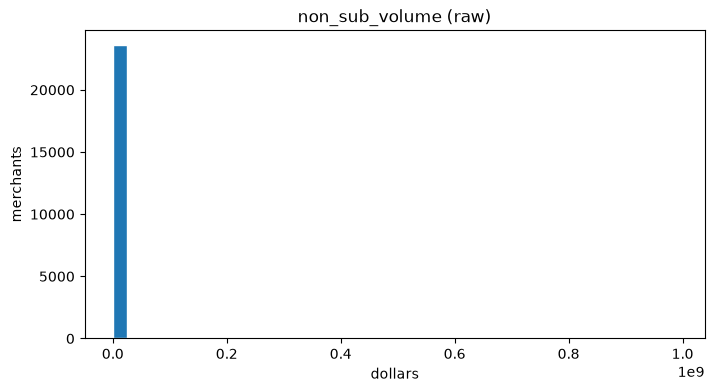

In [11]:
volume = merchants["non_sub_volume"]
print(f"zero: {(volume == 0).mean():.1%} of merchants, skewness: {volume.skew():.1f}")

fig, ax = plt.subplots(figsize=(8, 4))
plot_hist(ax, volume, "non_sub_volume (raw)", "dollars")
volume.describe()

Volume is extremely right skewed (skewness 96.7; median about \$1.8K, max about \$989M), so it enters the model as $\log(1 + V)$. The $+1$ keeps the 7% of merchants with zero volume.

### 3.6 `checkout_volume` and `payment_link_volume`

In [12]:
products = merchants[["checkout_volume", "payment_link_volume"]]
pd.DataFrame({
    "% of merchants with zero": (products.eq(0).mean() * 100).round(1),
    "median among non-zero": products[products > 0].median().round(0),
})

,% of merchants with zero,median among non-zero
checkout_volume,88.9,2080.0
payment_link_volume,85.2,635.0


Both products are zero for most merchants (89% and 85%). A usage flag and log volume would be highly correlated, so each product keeps only log volume; it is 0 for non-users, so whether the merchant uses the product is still captured.

| Covariate | Definition |
|---|---|
| `log_checkout_volume` | $\log(1 + \text{checkout\_volume})$ |
| `log_payment_link_volume` | $\log(1 + \text{payment\_link\_volume})$ |

### 3.7 Activity: `active_days`, `first_seen`, `last_seen`

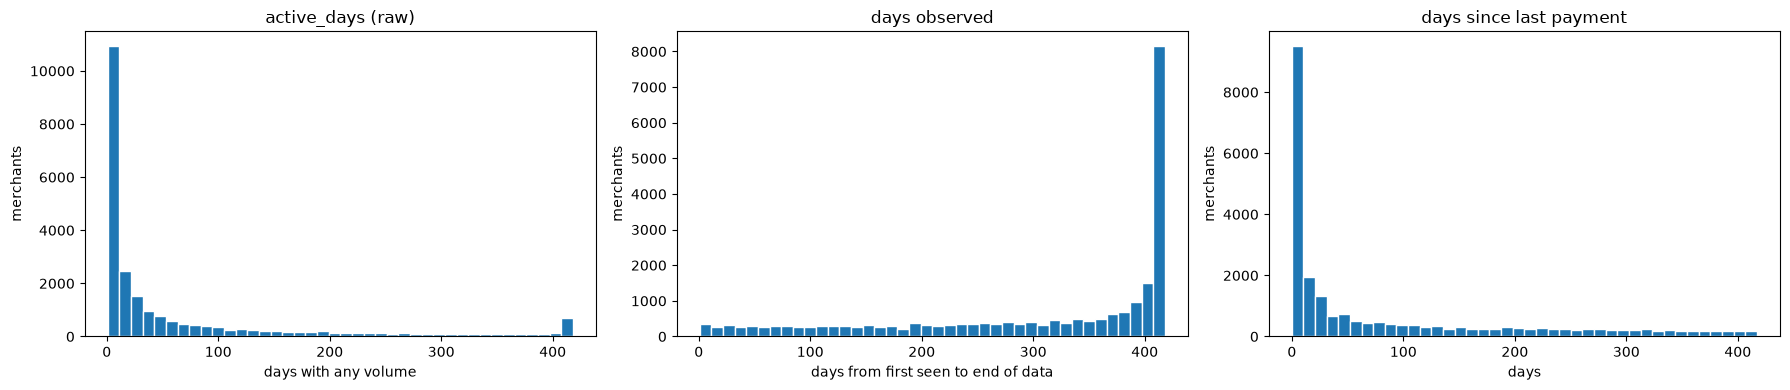

In [13]:
observed_days = (END - merchants["first_seen"]).dt.days + 1
days_since_last = (END - merchants["last_seen"]).dt.days

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
plot_hist(axes[0], merchants["active_days"], "active_days (raw)", "days with any volume")
plot_hist(axes[1], observed_days, "days observed", "days from first seen to end of data")
plot_hist(axes[2], days_since_last, "days since last payment", "days")
fig.tight_layout()

`active_days` is capped by how long a merchant has been observed, so activity enters as two covariates:

| Covariate | Definition |
|---|---|
| `active_rate` | active days ÷ days observed, in $(0, 1]$ |
| `recency` | days since the last payment |

## 4. Covariates

Apply the decisions in section 3. `first_charge_date` is kept as is.

In [14]:
CUT = 0.05  # classes below 5% of merchants are merged

REGIONS = {
    "Western & Northern Europe": ["DE", "IE", "CH", "NL", "BE", "AT", "LU", "SE", "NO", "DK", "FI", "EE", "LV", "LT"],
    "Southern & Eastern Europe": ["ES", "IT", "PT", "GR", "SI", "HR", "MT", "GI", "CY", "PL", "RO", "CZ", "SK", "BG", "HU"],
    "Rest of world": ["JP", "IN", "NZ", "HK", "SG", "MY", "TH", "AE", "MX", "BR"],
}
region_of = {code: region for region, codes in REGIONS.items() for code in codes}


def large_classes(col):
    share = merchants[col].value_counts(normalize=True)
    return share.index[share >= CUT]


industry = merchants["industry"].astype("object")
industry = industry.where(industry.isin(large_classes("industry")), "Others")  # missing -> Others too

country = merchants["country"].astype(str)
country = country.where(country.isin(large_classes("country")), country.map(region_of))
assert country.notna().all(), "a country has no region"

covariates = pd.DataFrame({
    "industry": industry.astype("category"),
    "country": country.astype("category"),
    "business_size": pd.Categorical(np.where(merchants["business_size"] == "small", "small", "medium/large")),
    "first_charge_date": merchants["first_charge_date"],
    "log_volume": np.log1p(merchants["non_sub_volume"]),
    "log_checkout_volume": np.log1p(merchants["checkout_volume"]),
    "log_payment_link_volume": np.log1p(merchants["payment_link_volume"]),
    "active_rate": merchants["active_days"] / observed_days,
    "recency": days_since_last,
}, index=merchants.index)

COVARIATES_PATH.parent.mkdir(parents=True, exist_ok=True)
covariates.to_pickle(COVARIATES_PATH)
covariates.head()

,industry,country,business_size,first_charge_date,log_volume,log_checkout_volume,log_payment_link_volume,active_rate,recency
merchant,,,,,,,,,
00085cb5,Software,Southern & Eastern Europe,small,2041-01-28,10.851296,10.851296,0.0,0.115385,15
000a45ba,Others,US,small,2040-06-01,6.216606,0.000000,0.0,0.095855,1
000e2c0e,Education,Rest of world,small,2039-09-21,8.448878,0.000000,0.0,0.178922,17
001111d7,Others,Southern & Eastern Europe,small,2042-04-24,9.834188,0.000000,0.0,0.150000,0
0015c036,Others,US,small,2041-02-27,0.000000,4.934474,0.0,0.164649,44


In [15]:
column_summary(covariates)

,dtype,missing,levels,most common,count,min,25%,50%,75%,99%,max
industry,category,0,9,Others,9112,,,,,,
country,category,0,8,US,8592,,,,,,
business_size,category,0,2,small,22845,,,,,,
first_charge_date,datetime64[us],26,,,,2030-11-07,2039-06-25,2040-12-06,2041-09-22,2042-06-13,2042-06-22
log_volume,float64,0,,,,0.0,4.92,7.49,9.61,14.29,20.71
log_checkout_volume,float64,0,,,,0.0,0.0,0.0,0.0,11.48,16.6
log_payment_link_volume,float64,0,,,,0.0,0.0,0.0,0.0,9.94,14.01
active_rate,float64,0,,,,0.0,0.02,0.06,0.25,1.0,1.0
recency,int64,0,,,,0.0,2.0,22.0,147.0,405.0,417.0


In [16]:
# Classes of the discrete covariates
pd.concat({
    col: covariates[col].value_counts().to_frame("merchants").assign(**{"% of merchants": lambda t: (t["merchants"] / len(covariates) * 100).round(1)})
    for col in ["industry", "country", "business_size"]
})

merchants  % of merchants
industry      Others                          9112            38.6
              Business services               3143            13.3
              Software                        2167             9.2
              Merchandise                     1987             8.4
              Personal services               1922             8.1
              Digital goods                   1379             5.8
              Education                       1331             5.6
              Clothing & accessory            1303             5.5
              Food & drink                    1275             5.4
country       US                              8592            36.4
              GB                              3476            14.7
              Southern & Eastern Europe       2446            10.4
              Western & Northern Europe       2384            10.1
              Rest of world                   2320             9.8
              FR                              1700             7.2
              AU                              1378             5.8
              CA                              1323             5.6
business_size small                          22845            96.7
              medium/large                     774             3.3